## Importing Libraries

In [ ]:
!pip install -q tf-keras

In [ ]:
import PIL.Image as Image
import cv2
import numpy as np

import matplotlib.pylab as plt

import tensorflow as tf
import tensorflow_hub as hub

from tensorflow import keras
from keras import layers,losses
from keras.models import Sequential

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

local_zip = '/content/drive/MyDrive/archive (1).zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/content/drive/MyDrive/dogs_cats_classification')
zip_ref.close()

In [ ]:
import pathlib
train_dir = pathlib.Path("/content/drive/MyDrive/dogs_cats_classification/training_set/training_set")
test_dir=pathlib.Path("/content/drive/MyDrive/dogs_cats_classification/test_set/test_set")

print(train_dir)
print(test_dir)

/content/drive/MyDrive/dogs_cats_classification/training_set/training_set
/content/drive/MyDrive/dogs_cats_classification/test_set/test_set


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats"  # غيّر المسار إلى مجلد البيانات لديك

deleted_count = 0

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file == "_DS_Store":
            file_path = os.path.join(root, file)
            os.remove(file_path)
            print(f"تم حذف: {file_path}")
            deleted_count += 1

print(f"\nتم حذف {deleted_count} ملف/ملفات .DS_Store")

تم حذف: /content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/_DS_Store

تم حذف 1 ملف/ملفات .DS_Store


In [ ]:
list(train_dir.glob('*/*'))[:5]

[PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/cat.684.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/cat.685.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/cat.686.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/cat.687.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/cats/cat.688.jpg')]

In [ ]:
cat_train= list(train_dir.glob('cats/*'))
len(cat_train)

4001

In [ ]:
image_count= len(list(train_dir.glob('*/*.jpg')))
image_count

8005

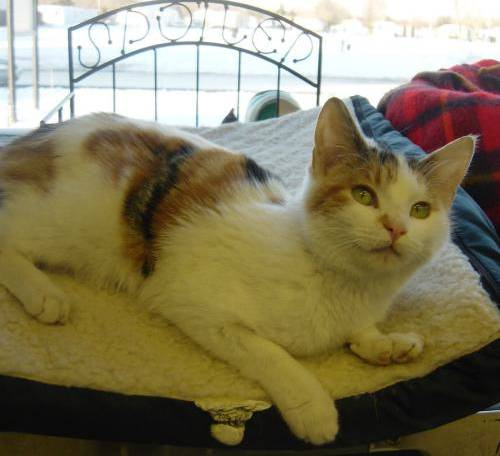

In [ ]:
Image.open(str(cat_train[1500]))

In [ ]:
dog_train= list(train_dir.glob('dogs/*'))
len(cat_train)

4001

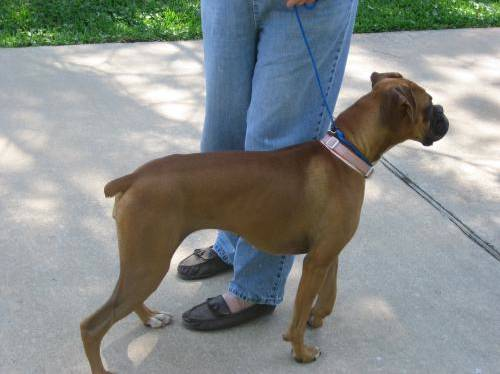

In [ ]:
Image.open(str(dog_train[1569]))

In [ ]:
images_dict = {
    'cats': cat_train[:2200],
    'dogs': dog_train[:2200],
}

In [ ]:
images_dict["dogs"][:5]

[PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/dogs/dog.3701.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/dogs/dog.3702.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/dogs/dog.3703.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/dogs/dog.3704.jpg'),
 PosixPath('/content/drive/MyDrive/dogs_cats_classification/training_set/training_set/dogs/dog.3705.jpg')]

In [ ]:
labels_dict = {
    'cats': 0,
    'dogs': 1,

}

In [ ]:
img= cv2.imread(str(images_dict['cats'][0]))

In [ ]:
img.shape

(499, 483, 3)

In [ ]:

import cv2
import numpy as np
from pathlib import Path

X, y = [], []
failed_images = []

for name, images in images_dict.items():
    for image in images:
        image_path = Path(image)

        # التحقق من وجود الملف
        if not image_path.is_file():
            print(f"الملف غير موجود: {image_path}")
            failed_images.append(str(image_path))
            continue

        # قراءة الصورة
        img = cv2.imread(str(image_path))

        # التحقق من نجاح القراءة
        if img is None or img.size == 0:
            print(f"تعذرت قراءة الصورة: {image_path}")
            failed_images.append(str(image_path))
            continue

        # تغيير أبعاد الصورة
        resize_img = cv2.resize(img, (224, 224))

        X.append(resize_img)
        y.append(labels_dict[name])

print(f"\nعدد الصور التي تمت معالجتها: {len(X)}")
print(f"عدد الصور التي تعذرت معالجتها: {len(failed_images)}")


In [ ]:

X, y = [], []
for name,images in images_dict.items():#returns key , path for each record
    for image in images:
        img=cv2.imread(str(image))
        resize_img=cv2.resize(img,(224,224))

        X.append(resize_img)
        y.append(labels_dict[name])

In [ ]:
X = np.array(X)
y = np.array(y)

In [ ]:
X.shape,y.shape

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.30 ,random_state=0)

In [ ]:
feature_extractor_model = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"

pretrained_model_without_top_layer = hub.KerasLayer(
    feature_extractor_model, input_shape=(224, 224, 3), trainable=False)

In [ ]:
import tf_keras



model = tf_keras.Sequential([
    pretrained_model_without_top_layer,
    tf_keras.layers.Dense(2)
])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 2260546 (8.62 MB)
Trainable params: 2562 (10.01 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


In [ ]:
# Scaling the image
X_train_scaled = X_train / 255
X_val_scaled = X_val / 255

##Model training

In [ ]:
import numpy as np

print("X_train shape:", X_train_scaled.shape)
print("X_train dtype:", X_train_scaled.dtype)
print("X_train size (GB):", X_train_scaled.nbytes / (1024**3))

print("X_val shape:", X_val_scaled.shape)
print("X_val dtype:", X_val_scaled.dtype)
print("X_val size (GB):", X_val_scaled.nbytes / (1024**3))

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (3080, 224, 224, 3)
X_train dtype: float64
X_train size (GB): 3.45428466796875
X_val shape: (1320, 224, 224, 3)
X_val dtype: float64
X_val size (GB): 1.48040771484375
y_train shape: (3080,)
y_val shape: (1320,)


In [ ]:
X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)

In [ ]:
model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['acc']
)
history = model.fit(X_train_scaled, y_train,validation_data=(X_val_scaled,y_val),epochs=5)

Epoch 1/5
97/97 [==============================] - 15s 96ms/step - loss: 0.1380 - acc: 0.9490 - val_loss: 0.0694 - val_acc: 0.9720
Epoch 2/5
97/97 [==============================] - 6s 59ms/step - loss: 0.0555 - acc: 0.9821 - val_loss: 0.0517 - val_acc: 0.9818
Epoch 3/5
97/97 [==============================] - 6s 62ms/step - loss: 0.0419 - acc: 0.9851 - val_loss: 0.0489 - val_acc: 0.9818
Epoch 4/5
97/97 [==============================] - 6s 62ms/step - loss: 0.0334 - acc: 0.9893 - val_loss: 0.0451 - val_acc: 0.9833
Epoch 5/5
97/97 [==============================] - 6s 60ms/step - loss: 0.0281 - acc: 0.9935 - val_loss: 0.0462 - val_acc: 0.9841


##Plotting Accuracy and Loss

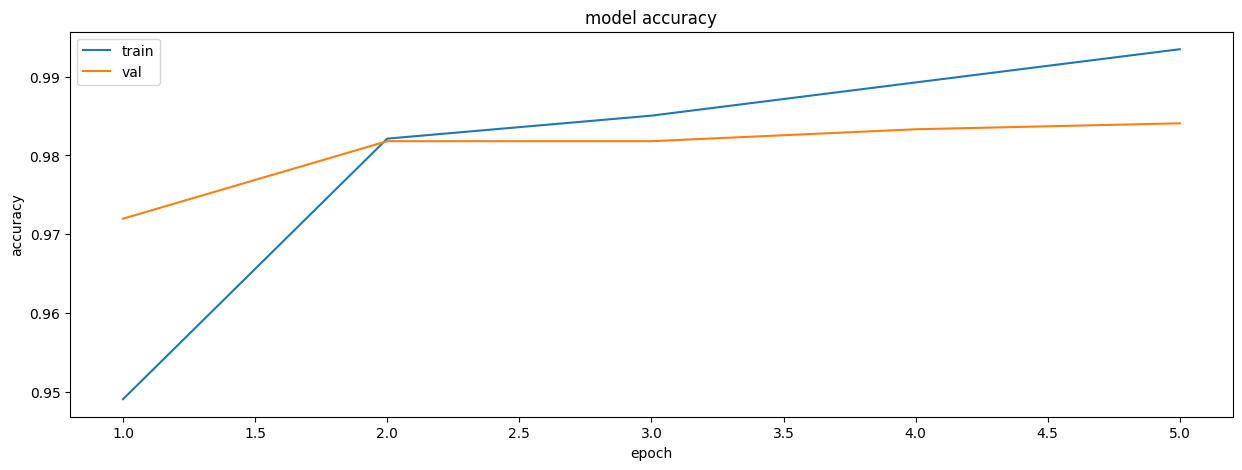

In [ ]:
plt.figure(figsize=(15,5))
epochs=range(1,len(history.history['val_acc'])+1)

plt.plot(epochs,history.history['acc'])
plt.plot(epochs,history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

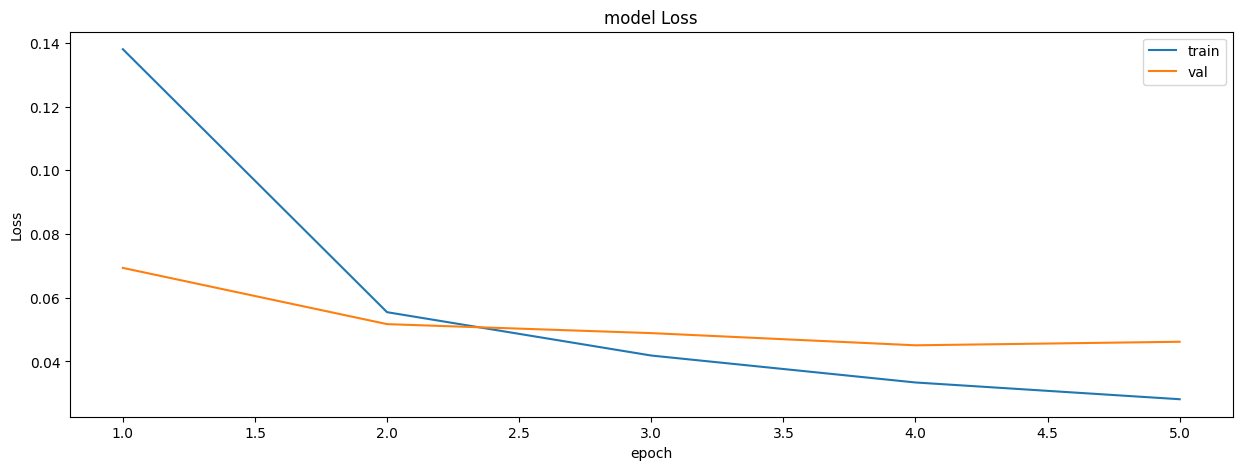

In [ ]:
plt.figure(figsize=(15,5))
epochs=range(1,len(history.history['val_loss'])+1)

plt.plot(epochs,history.history['loss'])
plt.plot(epochs,history.history['val_loss'])
plt.title('model Loss')
plt.ylabel('Loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.show()

## Making Test dataset for Prediction

In [ ]:
cat_test= list(test_dir.glob('cats/*'))
dog_test= list(test_dir.glob('dogs/*'))

In [ ]:
len (dog_test)

1012

In [ ]:
test_images_dict = {
    'cats': cat_test,
    'dogs': dog_test,
}

test_labels_dict = {
    'cats': 0,
    'dogs': 1,

}

In [ ]:
X_test, y_test = [], []
for name,images in test_images_dict.items():#returns key , path for each record
    for image in images:
        img=cv2.imread(str(image))

        resize_img=cv2.resize(img,(224,224))

        X_test.append(resize_img)
        y_test.append(test_labels_dict[name])

In [ ]:
X_test = np.array(X_test)
y_test = np.array(y_test)

In [ ]:
X_test.shape

(2023, 224, 224, 3)

In [ ]:
# Scaling the image
X_test_scaled = X_test / 255

In [ ]:
X_test_scaled = X_test_scaled.astype(np.float32)

## Fitting test data to check accuracy

In [ ]:
model.evaluate(X_test_scaled,y_test)

64/64 [==============================] - 4s 52ms/step - loss: 0.0493 - acc: 0.9842


[0.04931297525763512, 0.9841818809509277]

In [ ]:

# حفظ النموذج بعد انتهاء التدريب
model.save("/content/drive/MyDrive/dogs_cats_classification/cats_dogs_model.keras")

print("تم حفظ النموذج بنجاح!")

تم حفظ النموذج بنجاح!
